## Tool Calling

- Models can request to tools that perform tasks like such as fetching data from db,searching the web,or running code


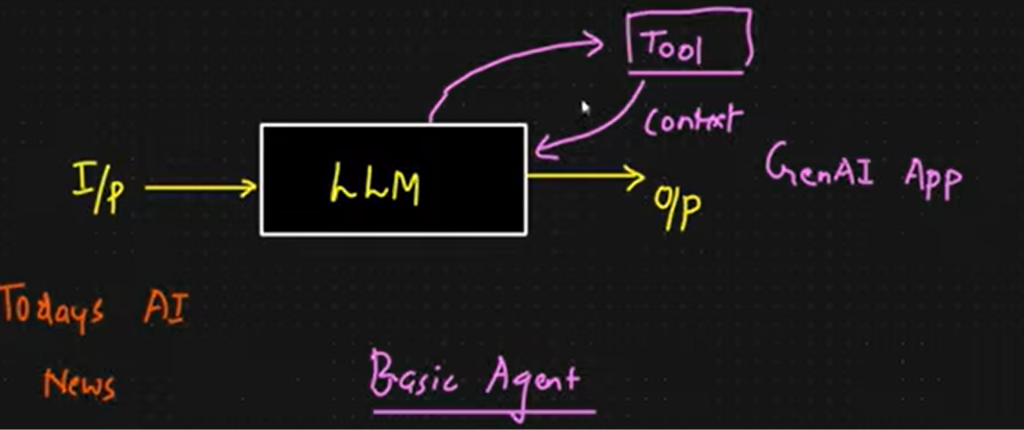

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ['OPENAI_API_KEY']=os.getenv('OPENAI_API_KEY')

In [4]:
from langchain.chat_models import init_chat_model
from langchain_openai import ChatOpenAI

model=init_chat_model(
  model='gpt-6-luna'
)

In [5]:
## Define a Tool
from langchain.tools import tool
@tool
def get_weather(location:str)->str:
  """" Get the Weather at this location """
  return f"The weather in this location {location} is sunny"

## Bind the model with tool
model_with_tools=model.bind_tools([get_weather])

In [7]:
## Now you have to invoke the model
response=model_with_tools.invoke("What is the weather in Himachal")
response.content

[{'arguments': '{"location":"Himachal"}',
  'call_id': 'call_FRuBhiSIGhSg7TzO7LyrtnVI',
  'name': 'get_weather',
  'type': 'function_call',
  'id': 'fc_069e8a296a47b882006ad320bbdb9887d1afce7bc7a2d19113',
  'status': 'completed'}]

### Tool Execution Loop

In [ ]:
# step-1: Generating the tool calls using models

messages=[{"role":"user","content":"what is the weather in Delhi"}]
ai_msg=model_with_tools.invoke(messages)
messages.append(ai_msg)
ai_msg.tool_calls

# step-2: Execute the tool calls and collected the results

for tool_call in ai_msg.tool_calls:
  ## executed the tool with generated arguments
  tool_result=get_weather.invoke(tool_call)
  messages.append(tool_result) 

# step-3: send back those tool result to model for final response
final_response=model_with_tools.invoke(messages)
print(final_response.text)

It’s sunny in Delhi.
